01_eda_telco.ipynb


# Analyse Exploratoire des Données — Telco Customer Churn

## 1. Contexte et objectifs

Ce notebook présente l'analyse exploratoire du jeu de données
**Telco Customer Churn** dans le cadre du projet d'analyse de
survie avec Deep Learning.

L'objectif est de comprendre les caractéristiques des clients,
d'identifier les facteurs associés à la résiliation (*churn*)
et d'étudier la durée avant résiliation.

Contrairement à une classification binaire classique, l'analyse
de survie prend également en compte les clients qui n'ont pas
encore résilié leur abonnement à la fin de la période observée.

### Objectifs de l'analyse

- Comprendre la structure et la qualité des données.
- Étudier la distribution des variables.
- Identifier les relations entre les caractéristiques des clients et le churn.
- Analyser les durées d'abonnement.
- Étudier les événements observés et les observations censurées.
- Explorer les courbes de survie selon différents segments.

### Source des données

Dataset : Telco Customer Churn

Fichier : `data/raw/telco-customer-churn.csv`

### Convention de survie

- `duration` : durée d'abonnement en mois (`tenure`).
- `event = 1` : résiliation observée (`Churn = Yes`).
- `event = 0` : client non résilié, observation censurée à droite (`Churn = No`).


In [1]:

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuration de l'analyse
RANDOM_SEED = 42

# Configuration de l'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Style des visualisations
sns.set_theme(style="whitegrid", palette="deep")

print("Imports réalisés avec succès.")
print(f"Version de pandas : {pd.__version__}")
print(f"Version de NumPy : {np.__version__}")


Imports réalisés avec succès.
Version de pandas : 2.3.3
Version de NumPy : 1.26.4


In [2]:
from pathlib import Path
import pandas as pd

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]

PROJECT_ROOT = next(
    (
        path for path in candidates
        if (path / "data" / "raw" / "telco-customer-churn.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Dataset introuvable depuis : {cwd}")

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "telco-customer-churn.csv"

print("Répertoire courant :", cwd)
print("Racine du projet :", PROJECT_ROOT)
print("Dataset trouvé :", DATA_PATH.exists())

df_raw = pd.read_csv(DATA_PATH)

print(f"Dimensions du dataset : {df_raw.shape}")
display(df_raw.head())

Répertoire courant : D:\Projects\survival-churn-deeplearning\notebooks
Racine du projet : D:\Projects\survival-churn-deeplearning
Dataset trouvé : True
Dimensions du dataset : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
display(df_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Nombre de valeurs manquantes classiques
print("Valeurs manquantes par colonne :")
display(df_raw.isna().sum().sort_values(ascending=False))

# Nombre de chaînes vides ou composées d'espaces
empty_values = (
    df_raw.select_dtypes(include="object")
    .apply(lambda col: col.str.strip().eq("").sum())
)

print("\nChaînes vides par colonne :")
display(empty_values[empty_values > 0])

Valeurs manquantes par colonne :


customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
OnlineBackup        0
gender              0
OnlineSecurity      0
InternetService     0
MultipleLines       0
PhoneService        0
tenure              0
Dependents          0
Partner             0
SeniorCitizen       0
Churn               0
dtype: int64


Chaînes vides par colonne :


TotalCharges    11
dtype: int64

In [6]:
# Afficher les clients dont TotalCharges est vide
mask_empty = df_raw["TotalCharges"].str.strip().eq("")

display(
    df_raw.loc[
        mask_empty,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [7]:
print("Nombre de lignes dupliquées :", df_raw.duplicated().sum())

print(
    "Nombre de customerID uniques :",
    df_raw["customerID"].nunique()
)

Nombre de lignes dupliquées : 0
Nombre de customerID uniques : 7043


In [8]:
# Variables numériques
numeric_cols = ["SeniorCitizen", "tenure", "MonthlyCharges"]

display(
    df_raw[numeric_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


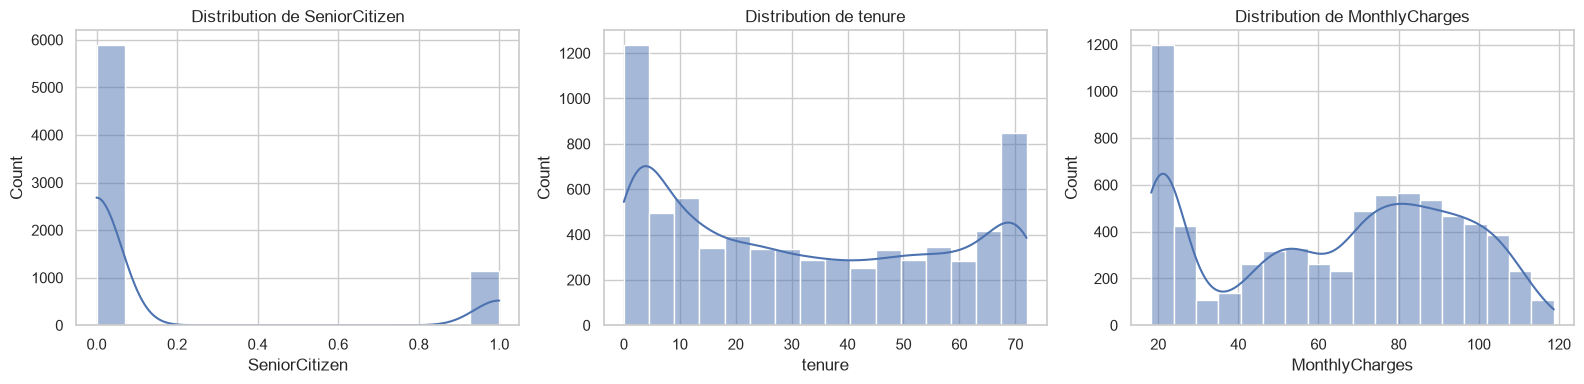

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df_raw, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution de {col}")

plt.tight_layout()
plt.show()

In [10]:
display(df_raw["SeniorCitizen"].value_counts().rename(index={0: "Non senior", 1: "Senior"}))

SeniorCitizen
Non senior    5901
Senior        1142
Name: count, dtype: int64

In [11]:
print("Ancienneté la plus fréquente :")
print(df_raw["tenure"].mode().iloc[0])

print("\nNombre de clients par tranche d'ancienneté :")
display(
    pd.cut(
        df_raw["tenure"],
        bins=[-1, 12, 24, 36, 48, 60, 72],
        labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
    ).value_counts().sort_index()
)

Ancienneté la plus fréquente :
1

Nombre de clients par tranche d'ancienneté :


tenure
0-12     2186
13-24    1024
25-36     832
37-48     762
49-60     832
61-72    1407
Name: count, dtype: int64

In [12]:
print("Asymétrie :", round(df_raw["MonthlyCharges"].skew(), 3))
print("Frais mensuels les plus fréquents :")
display(df_raw["MonthlyCharges"].value_counts().head(10))

Asymétrie : -0.221
Frais mensuels les plus fréquents :


MonthlyCharges
20.05    61
19.85    45
19.95    44
19.90    44
20.00    43
19.70    43
19.65    43
19.55    40
20.15    40
19.75    39
Name: count, dtype: int64

In [13]:
# Effectifs et pourcentages de churn
churn_counts = df_raw["Churn"].value_counts()
churn_percentages = df_raw["Churn"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    "Effectif": churn_counts,
    "Pourcentage": churn_percentages.round(2)
})

display(churn_summary)

,Effectif,Pourcentage
Churn,,
No,5174,73.46
Yes,1869,26.54


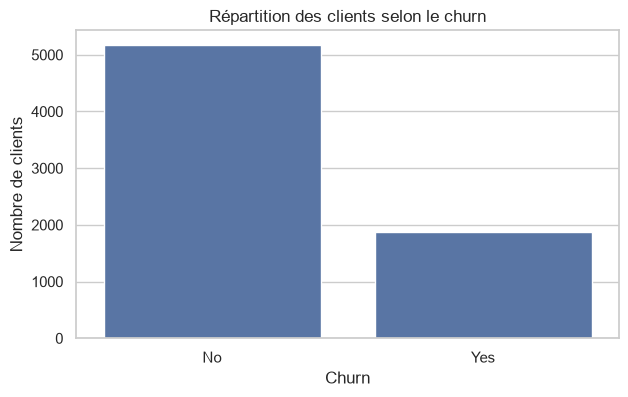

In [14]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df_raw, x="Churn")

plt.title("Répartition des clients selon le churn")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")

plt.show()

In [15]:
# Statistiques de tenure selon le churn
display(
    df_raw.groupby("Churn")["tenure"]
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


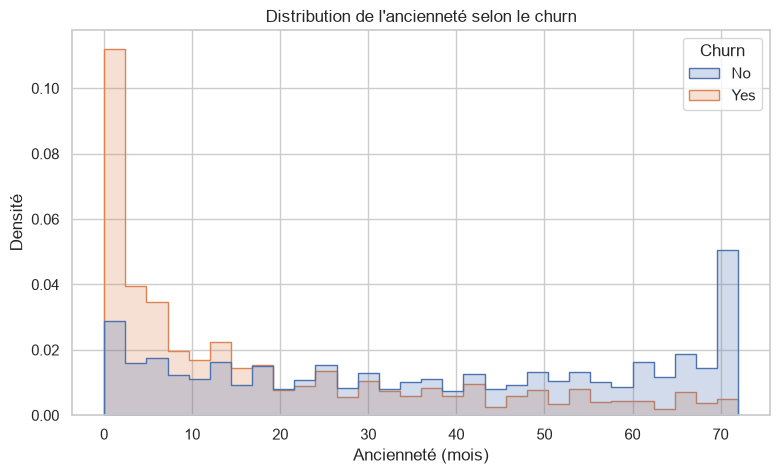

In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_raw,
    x="tenure",
    hue="Churn",
    bins=30,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution de l'ancienneté selon le churn")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Densité")

plt.show()

In [17]:
churn_by_contract = pd.crosstab(
    df_raw["Contract"],
    df_raw["Churn"],
    normalize="index"
) * 100

display(churn_by_contract.round(2))

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [18]:
churn_by_payment = pd.crosstab(
    df_raw["PaymentMethod"],
    df_raw["Churn"],
    normalize="index"
) * 100

display(churn_by_payment.round(2))

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [19]:
churn_by_internet = pd.crosstab(
    df_raw["InternetService"],
    df_raw["Churn"],
    normalize="index"
) * 100

display(churn_by_internet.round(2))

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [20]:
for col in ["OnlineSecurity", "TechSupport"]:
    print(f"\nTaux de churn selon {col} :")

    churn_by_service = pd.crosstab(
        df_raw[col],
        df_raw["Churn"],
        normalize="index"
    ) * 100

    display(churn_by_service.round(2))


Taux de churn selon OnlineSecurity :


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61



Taux de churn selon TechSupport :


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


In [21]:
try:
    from lifelines import KaplanMeierFitter
    print("Lifelines est disponible.")
except ImportError:
    print("Lifelines n'est pas installé.")

Lifelines est disponible.


In [22]:
from lifelines import KaplanMeierFitter

print("Lifelines est disponible.")

Lifelines est disponible.


In [23]:
# Préparation des données pour Kaplan-Meier

duration = df_raw["tenure"].to_numpy()

event = (
    df_raw["Churn"]
    .map({"Yes": 1, "No": 0})
    .to_numpy()
)

print("Nombre de clients :", len(duration))
print("Événements observés :", event.sum())
print("Observations censurées :", (event == 0).sum())

Nombre de clients : 7043
Événements observés : 1869
Observations censurées : 5174


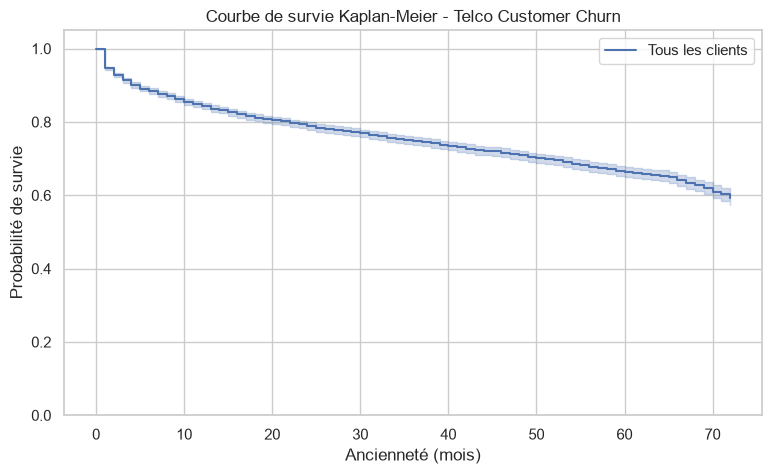

In [24]:
kmf = KaplanMeierFitter()

kmf.fit(
    durations=duration,
    event_observed=event,
    label="Tous les clients"
)

plt.figure(figsize=(9, 5))

kmf.plot_survival_function()

plt.title("Courbe de survie Kaplan-Meier - Telco Customer Churn")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Probabilité de survie")
plt.ylim(0, 1.05)
plt.grid(True)

plt.show()

In [25]:
print(
    "Médiane de survie estimée :",
    kmf.median_survival_time_,
    "mois"
)

Médiane de survie estimée : inf mois


In [26]:
survival_at_72 = kmf.predict(72)

print(
    f"Probabilité de survie estimée à 72 mois : "
    f"{survival_at_72:.2%}"
)

Probabilité de survie estimée à 72 mois : 59.28%


In [27]:
print("Dernière probabilité de survie :", kmf.survival_function_.iloc[-1, 0])

Dernière probabilité de survie : 0.5927901520522275


### Analyse de la survie globale

L'estimateur de Kaplan-Meier permet d'étudier la probabilité de maintien des clients dans le service en tenant compte des observations censurées.

La probabilité de survie estimée à 72 mois est de **59,28 %**. La médiane de survie n'est pas atteinte durant la période d'observation, car la courbe reste au-dessus du seuil de 50 %.

Ce résultat souligne l'importance de prendre en compte la censure à droite dans l'analyse du churn, plutôt que de considérer uniquement la proportion de clients ayant quitté le service.

In [28]:
df_raw["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

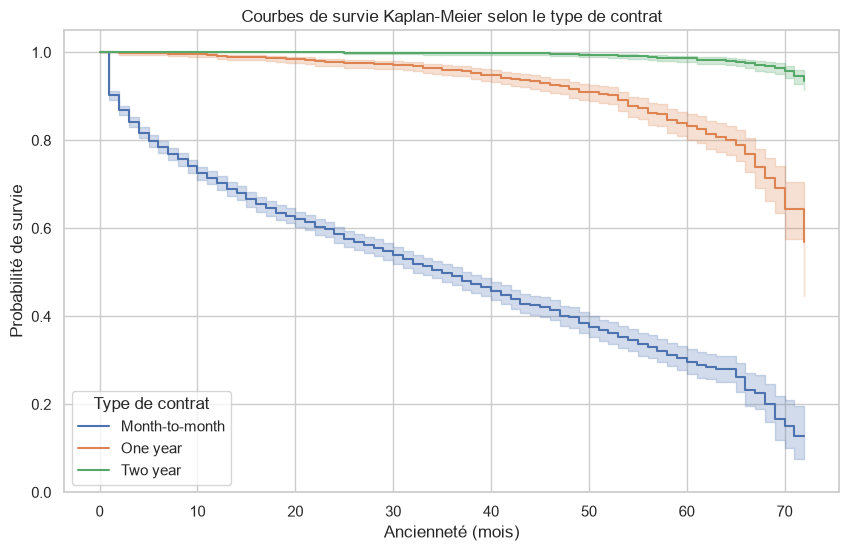

In [29]:
from lifelines import KaplanMeierFitter

plt.figure(figsize=(10, 6))

for contract in df_raw["Contract"].unique():
    mask = df_raw["Contract"] == contract

    kmf_contract = KaplanMeierFitter()

    kmf_contract.fit(
        durations=df_raw.loc[mask, "tenure"],
        event_observed=(df_raw.loc[mask, "Churn"] == "Yes").astype(int),
        label=contract
    )

    kmf_contract.plot_survival_function()

plt.title("Courbes de survie Kaplan-Meier selon le type de contrat")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Probabilité de survie")
plt.ylim(0, 1.05)
plt.legend(title="Type de contrat")
plt.grid(True)
plt.show()

In [30]:
from lifelines.statistics import multivariate_logrank_test

results = multivariate_logrank_test(
    event_durations=df_raw["tenure"],
    groups=df_raw["Contract"],
    event_observed=(df_raw["Churn"] == "Yes").astype(int)
)

results.print_summary()

### Comparaison de la survie selon le type de contrat

L'analyse des courbes de Kaplan-Meier révèle des différences importantes entre les trois catégories de contrats. Les clients ayant un contrat de deux ans présentent la meilleure probabilité de survie, suivis des clients ayant un contrat d'un an. Les contrats mensuels présentent la probabilité de survie la plus faible.

Le test Log-Rank multivarié confirme que ces différences sont statistiquement significatives (χ² = 2352,87 ; ddl = 2 ; p < 0,005).

Ces résultats indiquent une forte association entre le type de contrat et la fidélisation des clients. Toutefois, le test global ne permet pas d'identifier les différences entre chaque paire de groupes ni d'établir une relation de causalité.

In [31]:
from itertools import combinations
from lifelines.statistics import logrank_test

results = []

for contract_1, contract_2 in combinations(
    ["Month-to-month", "One year", "Two year"], 2
):
    group_1 = df_raw[df_raw["Contract"] == contract_1]
    group_2 = df_raw[df_raw["Contract"] == contract_2]

    test = logrank_test(
        group_1["tenure"],
        group_2["tenure"],
        event_observed_A=(group_1["Churn"] == "Yes").astype(int),
        event_observed_B=(group_2["Churn"] == "Yes").astype(int)
    )

    results.append({
        "Comparaison": f"{contract_1} vs {contract_2}",
        "Chi2": test.test_statistic,
        "p-value": test.p_value
    })

results_df = pd.DataFrame(results)

# Correction de Bonferroni
results_df["p-value ajustée"] = (
    results_df["p-value"] * len(results_df)
).clip(upper=1.0)

results_df["Significatif"] = (
    results_df["p-value ajustée"] < 0.05
)

results_df

,Comparaison,Chi2,p-value,p-value ajustée,Significatif
0,Month-to-month vs One year,926.064559,2.117327e-203,6.351980e-203,True
1,Month-to-month vs Two year,1550.510307,0.000000e+00,0.000000e+00,True
2,One year vs Two year,256.217767,1.145448e-57,3.436345e-57,True


### Comparaisons deux à deux : test Log-Rank avec correction de Bonferroni

Les comparaisons deux à deux confirment l'existence de différences statistiquement significatives entre les trois catégories de contrats.

Après correction de Bonferroni, les trois comparaisons présentent une p-value ajustée inférieure au seuil de 0,05 :

- Month-to-month vs One year : différence significative.
- Month-to-month vs Two year : différence significative.
- One year vs Two year : différence significative.

Ces résultats confirment que les fonctions de survie diffèrent significativement entre chaque paire de catégories de contrats.

En complément de l'analyse des courbes de Kaplan-Meier, les résultats montrent une association importante entre la durée du contrat et la rétention des clients. Les contrats de deux ans présentent la meilleure survie estimée, suivis des contrats d'un an, puis des contrats mensuels.

# 7. Synthèse générale de l'EDA

## 7.1. Qualité et caractéristiques des données

Le dataset Telco Customer Churn contient 7 043 clients et 21 variables décrivant leurs caractéristiques démographiques, leurs services, leurs contrats et leur comportement.

L'exploration a révélé 11 valeurs vides dans la colonne `TotalCharges`. Ces observations correspondent à des clients ayant une ancienneté de zéro mois. Ces valeurs ont été remplacées par 0 lors du prétraitement, sans supprimer les clients concernés.

Aucun doublon n'a été détecté et chaque client possède un identifiant unique.

## 7.2. Analyse du churn et de la censure

Sur les 7 043 clients, 1 869 départs ont été observés, soit 26,54 % des observations. Les 5 174 autres clients, représentant 73,46 %, sont considérés comme censurés à droite.

Cette proportion importante de censure justifie l'utilisation des méthodes d'analyse de survie, qui permettent d'exploiter les informations disponibles sans considérer les clients censurés comme des clients qui ne partiront jamais.

## 7.3. Facteurs associés au churn

L'analyse bivariée a mis en évidence plusieurs associations :

- **Type de contrat :** le taux de churn est particulièrement élevé pour les contrats mensuels (42,71 %), contre 11,27 % pour les contrats d'un an et 2,83 % pour les contrats de deux ans.
- **Méthode de paiement :** le paiement par chèque électronique présente un taux de churn de 45,29 %, supérieur aux autres méthodes.
- **Service Internet :** les clients utilisant la fibre optique présentent un taux de churn de 41,89 %.
- **Services de sécurité et d'assistance :** les clients ne dispos